# Снижение активности по картам: кто, насколько и за счёт чего

**Автор:**
**Период данных:** 2024-01-01 — 2025-06-30
**Подготовлено для:** департамент розничных продуктов, банк «Меридиан»

<!--
Этот ноутбук собирается в HTML командой:
jupyter nbconvert --to html --no-input --execute 02_report.ipynb --output report.html

Поэтому: кода читатель не видит, все графики и таблицы получены
исполнением, числа в тексте должны совпадать с выводом кода.
Лимит: 6 страниц и 8 графиков.
-->

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

clean = pd.read_parquet("clean_data.parquet")

## 1. Главное

<!-- 3–5 выводов с числами. Пишется последним, читается первым.
     Каждый вывод — утверждение, а не тема. Не «анализ активности»,
     а «активность упала на X% у группы Y за счёт Z». -->

1.
2.
3.

## 2. Контекст

<!-- Какое решение поддерживает этот отчёт, 3–5 предложений. -->

### За последние полгода банк видит, что клиенты стали реже пользоваться картами. Необходимо проанализировать активность клиентов банка за январь–июнь 2024 и январь–июнь 2025 года, выявить клиентов со снижением частоты использования банковских карт и выделить от 3 до 5 целевых групп численностью не менее 150 человек каждая.
**Итоговая цель** — сформировать обоснованные клиентские сегменты, для которых банк сможет разработать адресные маркетинговые предложения с учётом предполагаемых причин снижения карточной активности.

## 3. Данные и ограничения

<!-- Период, число клиентов и операций, что и почему исключено из расчёта,
     чего в данных нет.

     Здесь же одним абзацем: какую метрику активности вы выбрали,
     как она считается и какое снижение она не увидит. -->

### Предобработка данных

В ходе предобработки данных:
- Удалены полные дубликаты строк.
- Исключены транзакции со статусом, отличным от «успешно».
- Наименования городов и типов транзакций приведены к единому формату внутри категорий.
- Исключены записи с отрицательными значениями ежемесячного дохода.
- Оставлены транзакции за период с 01.01.2024 по 30.06.2025. Операции за пределами указанного периода исключены из анализа.


### Методология оценки активности клиентов

- В качестве показателя активности используется количество успешно проведённых транзакций по карте и токену.
- Для сравнения выбраны периоды январь–июнь 2024 и январь–июнь 2025. Это позволяет учесть сезонность расходов и снизить её влияние на результаты.
- Расчёты проведены по всей клиентской базе. При дальнейшем формировании групп для коммуникации отобраны только клиенты, давшие согласие на маркетинговые коммуникации.
- Учтено ограничение метрики: она не отражает снижение денежных оборотов, среднего чека и переход клиентов на другие способы оплаты.

## 4. Находки

<!-- По одной находке на подраздел. Заголовок подраздела — вывод,
     а не тема. Под заголовком: график или таблица, затем 2–4
     предложения. -->

### 4.1. 

### **Сезонность активности клиентов** Количество транзакций отличается в зависимости от месяца и такую тенденцию можно наблюдать на разных годах

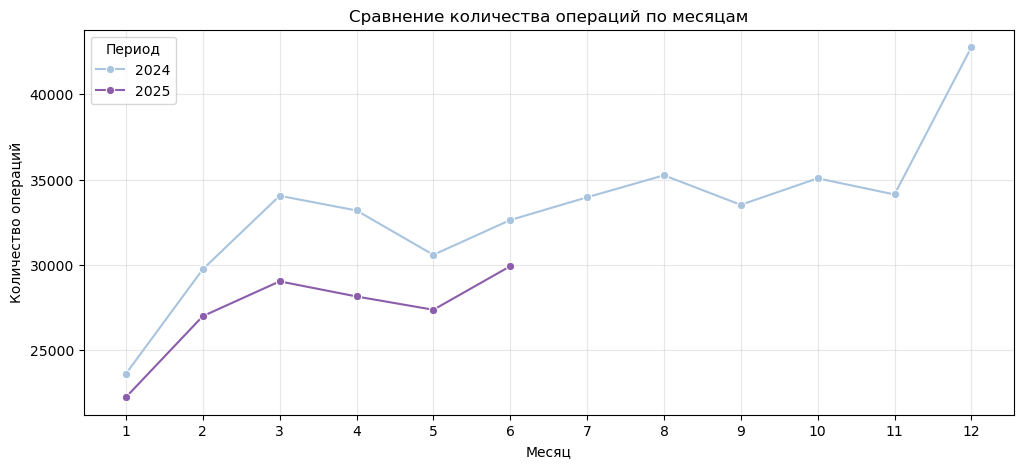

In [17]:
monthly_2024 = (
    clean[clean['txn_datetime'].dt.year == 2024]
    .groupby(clean[clean['txn_datetime'].dt.year == 2024]['txn_datetime'].dt.month)
    .size()
    .reindex(range(1, 13), fill_value=0)
    .reset_index(name='Количество операций')
)

monthly_2024['Период'] = '2024'

monthly_2025 = (
    clean[clean['txn_datetime'].between('2025-01-01', '2025-06-30')]
    .groupby(clean[clean['txn_datetime'].between('2025-01-01', '2025-06-30')]['txn_datetime'].dt.month)
    .size()
    .reindex(range(1, 7), fill_value=0)
    .reset_index(name='Количество операций')
)

monthly_2025['Период'] = '2025'

monthly = pd.concat([monthly_2024, monthly_2025])
monthly.columns = ['Месяц', 'Количество операций', 'Период']

plt.figure(figsize=(12, 5))

sns.lineplot(
    data=monthly,
    x='Месяц',
    y='Количество операций',
    hue='Период',
    marker='o',
    palette='BuPu'
)

plt.title('Сравнение количества операций по месяцам')
plt.xlabel('Месяц')
plt.ylabel('Количество операций')
plt.xticks(range(1, 13))
plt.grid(alpha=0.3)
plt.legend(title='Период')
plt.show()

### 4.2. 

## **Несоответствие MCC-кодов категориям:** предполагаемая зависимость между MCC-кодом и категорией операции соблюдается не во всех случаях.

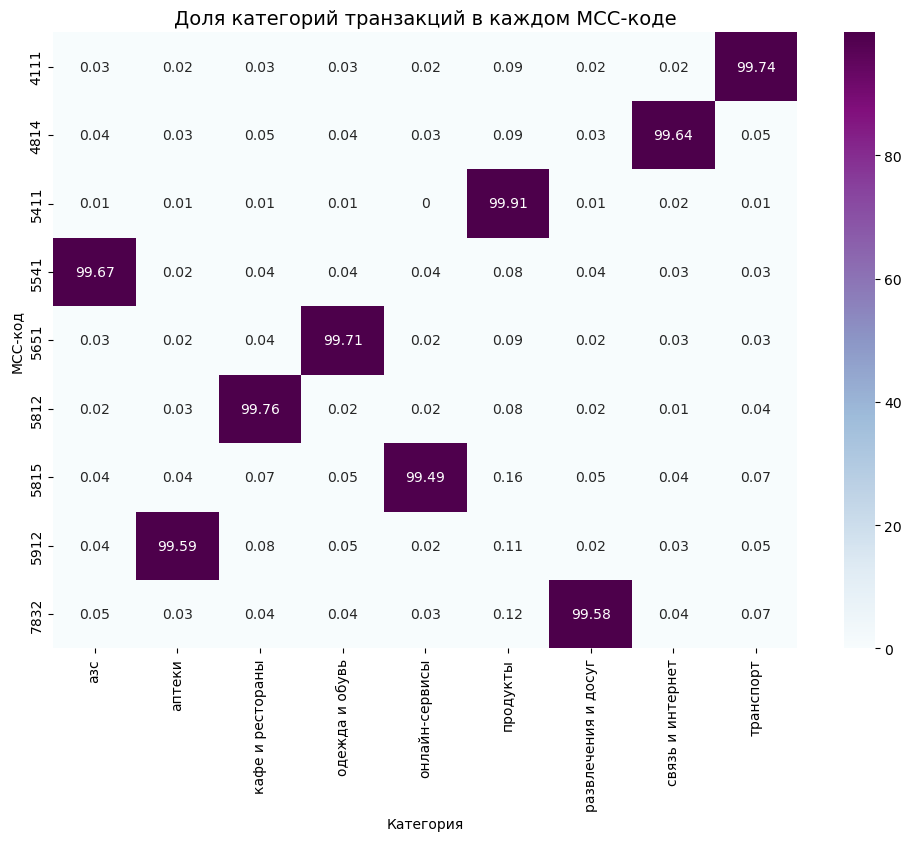

In [13]:
heatmap_data = (pd.crosstab(clean["mcc_code"], clean["category"], normalize='index') * 100).round(2)

plt.figure(figsize=(12, 8))
sns.heatmap(heatmap_data, annot=True, fmt="g", cmap="BuPu")

plt.title("Доля категорий транзакций в каждом MCC-коде", fontsize=14)
plt.xlabel("Категория")
plt.ylabel("MCC-код")
plt.show()

## 5. Группы для кампании

<!-- Таблица: группа, правило отбора, размер, причина падения.
     Ниже — по абзацу на группу. -->

## Выделенные группы клиентов

Для дальнейшей маркетинговой коммуникации выделены четыре группы клиентов, у которых количество транзакций в первой половине 2025 года снизилось относительно первой половины 2024 года Во все группы включены только клиенты, предоставившие согласие на маркетинговую коммуникацию.

1. **Клиенты без установленного мобильного приложения** - активность снизилась на 30% и более.

   Количество клиентов: **641**.

2. **Клиенты с кредитным типом карты** - активность снизилась

   Количество клиентов: **603**.

3. **Клиенты, у которых большинство транзакций приходилось на категорию "Продукты"** - активность снизилась на 36% и более.

   Количество клиентов: **519**.

4. **Клиенты массового сегмента, проживающие в Казани** - активность снизилась

   Количество клиентов: **237**.

## 6. Кого не включаем и почему

<!-- Отдельным списком. Для каждой категории: кто это, сколько их,
     почему кампания им не нужна или бесполезна. -->

## 7. Что проверили и что не подтвердилось

<!-- 3–5 строк, по одной на гипотезу, каждая с числом. -->

1. **Клиенты с низкой оценкой качества обслуживания.** Предполагалось, что среди клиентов, поставивших низкую оценку (1–2), снижение активности будет более выраженным. Однако среди клиентов со снизившейся активностью только 12% поставили оценку 1–2, 25% — оценку 3–5, остальные не оценивали качество. Таким образом, явной связи между низкой оценкой и снижением активности не выявлено. Поэтому данная категория не выделялась в отдельную группу.

2. **Отдельные сегменты клиентов, типы карт и источники дохода.** Предполагалось, что в некоторых категориях снижение активности будет более выраженным. Однако анализ показал, что соотношение категорий среди клиентов со снизившейся активностью существенно не изменилось. Следовательно, принадлежность к определённому сегменту, типу карты или источнику дохода не позволяет выделить отдельную группу клиентов с повышенным снижением активности.

## 8. Приложение

### 8.1. Сводка журнала изменений

<!-- 5–10 строк по типам нарушений: поле, что найдено, сколько строк,
     что сделано. Полный журнал — в cleaning_log.csv. -->

### 8.2. Методика

<!-- Точные формулы, фильтры, пороги и их значения. Всё, что нужно,
     чтобы повторить расчёт. -->

### 8.3. Использование ИИ

<!-- 3–5 строк: для чего использовали и что проверили сами. -->